# **WEEK 2 - EXPLORATORY DATA ANALYSIS: NEXTGENLEARNERS APPLICANT INSIGHTS**

# **Step 1: Setting Up The Working Environment**

In [15]:
import pandas as pd
import matplotlib.pyplot as plt # Used for creating charts
import seaborn as sns #Used for creating attractive statistical charts and graphs

df = pd.read_csv("applicants_cleaned.csv", parse_dates = ['Application_date'])

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

df

,Applicant_Name,Email,Phone,Domain_Applied,University_Name,Application_date,Status
0,Valerie Miller,melanie29@example.org,8093138551x7574,Web Development,Not provided,2026-05-12,Under Review
1,Robert Johnston,briansmith@example.org,568.788.3065x7244,Web Development,Moi University,2026-05-12,Under Review
2,Breanna Solis,christopher86@example.net,0018124354182x708,Web Development,Egerton University,2026-05-13,Selected
3,Dawn Kim,kristen00@example.com,976.444.1756x4317,Web Development,Egerton University,2026-05-12,Under Review
4,Derrick Moore,kolson@example.net,5909238996,Computer Science,Maseno University,2026-05-12,Selected
5,Jose Wells,donnaobrien@example.org,8907345073,Web Development,Not provided,2026-05-12,Under Review
6,Lucas Odonnell,fishermichael@example.org,3786250726,Web Development,Moi University,2026-05-13,Rejected
7,Ian Hoffman,atran@example.com,9598907482,Pure Mathematics,University of Nairobi,2026-05-12,Under Review
8,Mary Lee,amyharvey@example.org,9133507350,Web Development,JKUAT University,2026-05-12,Selected
9,Jamie Andrews,myersjohn@example.net,990.608.2287x5855,Web Development,Not provided,2026-05-13,Selected


In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Applicant_Name    96 non-null     str           
 1   Email             96 non-null     str           
 2   Phone             96 non-null     str           
 3   Domain_Applied    96 non-null     str           
 4   University_Name   96 non-null     str           
 5   Application_date  96 non-null     datetime64[us]
 6   Status            96 non-null     str           
dtypes: datetime64[us](1), str(6)
memory usage: 13.8 KB


- The DataFrame has 96 rows.
- The DataFrame has 7 columns; "Applicant_Name", "Email", "Phone", "Domain_Applied", "University_Name", "Application_date" and "Status".
- There are no missing values in columns.
- The DataFrame has 1 datetime column and 6 text columns.

In [18]:
df.head()#Display the first five rows in the dataset.

,Applicant_Name,Email,Phone,Domain_Applied,University_Name,Application_date,Status
0,Valerie Miller,melanie29@example.org,8093138551x7574,Web Development,Not provided,2026-05-12,Under Review
1,Robert Johnston,briansmith@example.org,568.788.3065x7244,Web Development,Moi University,2026-05-12,Under Review
2,Breanna Solis,christopher86@example.net,0018124354182x708,Web Development,Egerton University,2026-05-13,Selected
3,Dawn Kim,kristen00@example.com,976.444.1756x4317,Web Development,Egerton University,2026-05-12,Under Review
4,Derrick Moore,kolson@example.net,5909238996,Computer Science,Maseno University,2026-05-12,Selected


In [19]:
df.tail() #Display the last 5 rows in the dataset.

,Applicant_Name,Email,Phone,Domain_Applied,University_Name,Application_date,Status
91,Shawn Rush,joneskevin@example.com,+18076853378,Web Development,Not provided,2026-05-13,Selected
92,Morgan Decker,hchen@example.net,+15628794030x9956,Applied Statistics,Not provided,2026-05-12,Rejected
93,Daniel Carr,eric00@example.org,6908609789,Web Development,Not provided,2026-05-13,Rejected
94,Christopher Hernandez,curtischad@example.org,317.565.2152x716,Applied Statistics,Not provided,2026-05-12,Under Review
95,Susan Lee,Not_provided@gmail.com,8055089632x921,Data Science,JKUAT University,2026-05-12,Selected


# **Step 2: Meaning of EDA**
*EDA is the process of asking questions about your data and answering them using summary statistics  and charts, before you can jump into conclusions or build any model.*
*The goal isn't to prove a spcific point but to genuinely explore and let data show you patterns you might not have expected.*

# **Step 3: Which Domain Received The Most Applications?**

In [20]:
domain_counts = df['Domain_Applied'].value_counts()
print(domain_counts)

Domain_Applied
Web Development       55
Applied Statistics    19
Pure Mathematics       8
Computer Science       7
Data Science           7
Name: count, dtype: int64


Web Development recorded the highest number of applicants with 55 applicants while Computer Science and Data Science recorded the lowest number of applicants with 7 applicants each.

<Figure size 800x500 with 0 Axes>

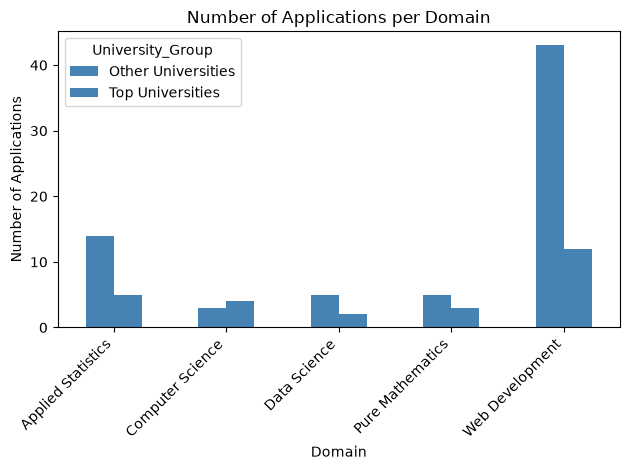

In [39]:
#Display the bar graph
plt.figure(figsize = (8, 5))
domain_counts.plot(kind = 'bar', color = 'steelblue')#Type of chart and color
plt.title('Number of Applications per Domain')#This is the title of the graph.
plt.xlabel('Domain')#label the x-axis
plt.ylabel('Number of Applications')#label the y-axis
plt.xticks(rotation = 45, ha = 'right')#Rotate the labels on the x-axis by 45 degrees and align them to the right, making the chart easier to read
plt.tight_layout()#Adjusts the chart's spacing so that the labels and title fit more neatly within the figure.
plt.show()#Display the chart


Web Development recorded the highest number of applicants with 55 applicants while Computer Science and Data Science recorded the lowest number of applicants with 7 applicants each.

# **Step 4: How did the Applications trend over time?**

In [22]:
#Group by month
df['Application_Month'] = df['Application_date'].dt.to_period('M')
monthly_trend = df.groupby('Application_Month').size()
print(monthly_trend)

Application_Month
2026-05    96
Freq: M, dtype: int64


*All application dates in the dataset fall within May. Therefore, a monthly trend analysis would not provide a meaningful comparison across different months because the dataset covers only one month.*

*To gain a clearer understanding of application patterns over time, a daily application trend analysis is more appropriate. This approach allows us to examine the number of applications received on each day and identify variations in daily application volumes.*

In [23]:
#Group by day
df['Application_Day'] = df['Application_date'].dt.to_period('D')
daily_trend = df.groupby('Application_Day').size()
print(daily_trend)

Application_Day
2026-05-12    50
2026-05-13    46
Freq: D, dtype: int64


*There are two distinct application dates in the dataset. Therefore, it is appropriate to explore the daily application trend to understand how the number of applications varies from one day to another.*

*Analyzing daily application trends helps identify days with high or low application volumes and provides a clearer picture of application activity over time.*

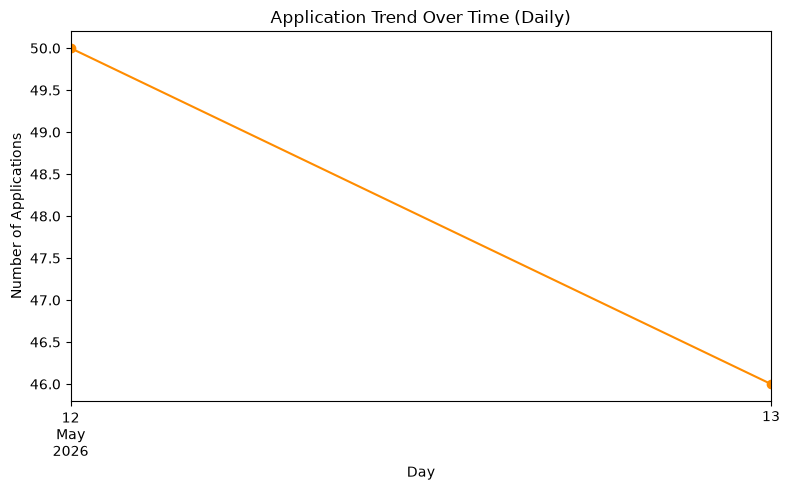

In [24]:
#The Visualizatiom(a line chart)
plt.figure(figsize = (8, 5))
daily_trend.plot(kind = 'line', marker = 'o', color = 'darkorange')
plt.title('Application Trend Over Time (Daily)')
plt.xlabel('Day')
plt.ylabel('Number of Applications')
plt.tight_layout()
plt.show()

*Applications spiked on 2026-05-12, likely correlating with the domain application announcement, then declined gradually through 2026-05-13 toward the application deadline.*

# **Step 5: What is the acceptance Rate - Overall and per domain?**

In [25]:
#Overall status Breakdown
status_counts = df['Status'].value_counts()
print(status_counts)

Status
Selected        48
Under Review    31
Rejected        17
Name: count, dtype: int64


Out of the 96 applications, 48 were selected, 31 were under review and 17 applications were rejected.

In [26]:
#Per_domain breakdown using pivot_table():
status_by_domain = pd. pivot_table(
    df,
    index = 'Domain_Applied',
    columns = 'Status',
    values = 'Applicant_Name',
    aggfunc = 'count',
    fill_value = 0
)
print(status_by_domain)

Status              Rejected  Selected  Under Review
Domain_Applied                                      
Applied Statistics         5         6             8
Computer Science           2         4             1
Data Science               1         3             3
Pure Mathematics           1         4             3
Web Development            8        31            16


Web Development recorded the highest number of selected applicants (31) while Data Science recorded the lowest number of selected applicants (3).

In [27]:
#It is efficient to work with percentages because percentages let you compare fairly across domains with different applications.
status_by_domain_pct = status_by_domain.div(status_by_domain.sum(axis = 1), axis = 0) * 100
print(status_by_domain_pct.round(1))

Status              Rejected  Selected  Under Review
Domain_Applied                                      
Applied Statistics      26.3      31.6          42.1
Computer Science        28.6      57.1          14.3
Data Science            14.3      42.9          42.9
Pure Mathematics        12.5      50.0          37.5
Web Development         14.5      56.4          29.1


*Web Development recorded the highest number of selected applicants, with 31 applicants and an acceptance rate of 56.4%. This indicates that Web Development had the largest number of successful applicants among the three domains. Its relatively high acceptance rate also suggests that just over half of its applicants were accepted.*

*Applied Statistics had 6 selected applicants, with an acceptance rate of 31.6%. Although the number of selected applicants was higher than in Computer Science, Applied Statistics had the lowest acceptance rate among the three domains. This means that a smaller proportion of its applicants were accepted.*

*Computer Science recorded 4 selected applicants and the highest acceptance rate, at 57.1%. Despite having the highest acceptance rate, it had the lowest number of selected applicants among the three domains. This illustrates an important point: a high acceptance rate does not necessarily mean a high number of selected applicants.*

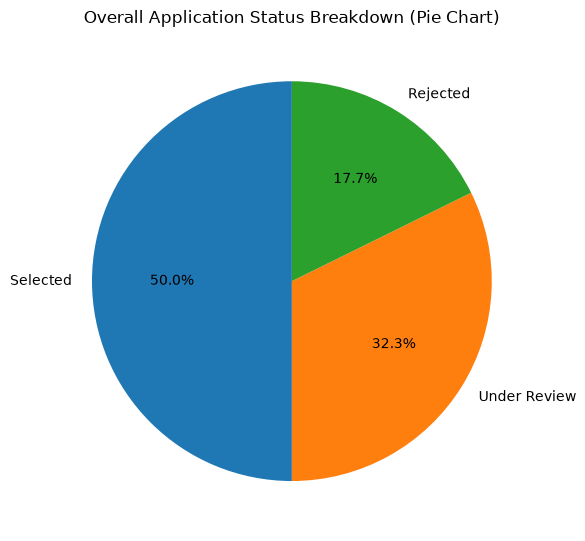

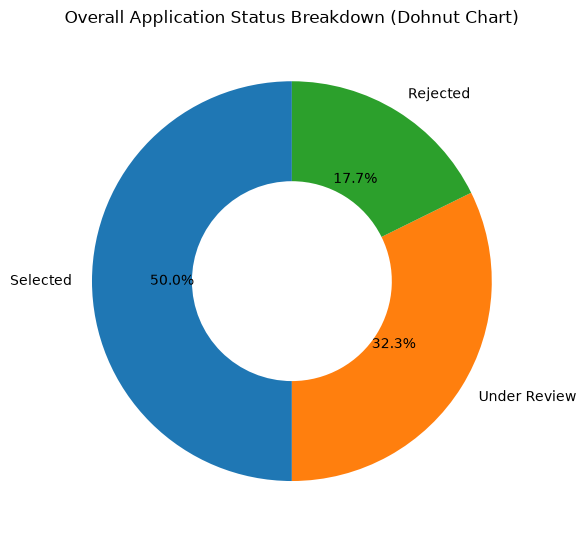

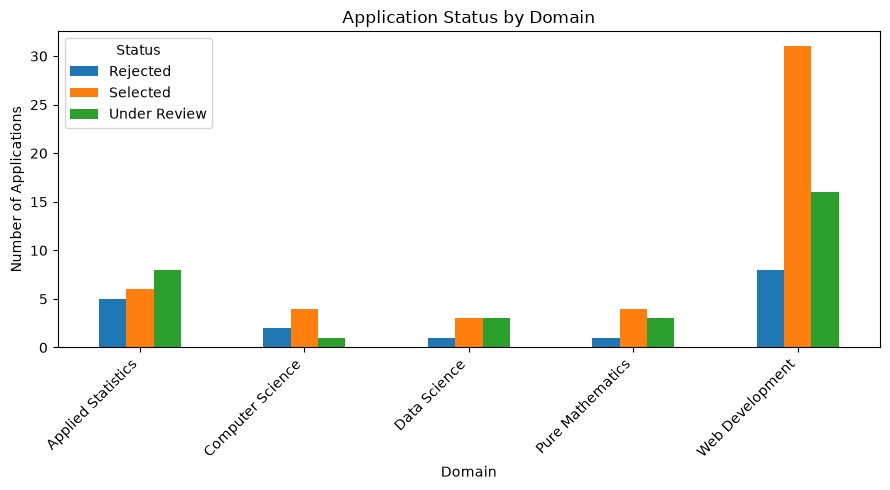

In [28]:
## Visualization
# Overall status - pie chart
plt.figure(figsize = (6, 6))
status_counts.plot(kind = 'pie', autopct = '%1.1f%%', startangle = 90)
plt.title('Overall Application Status Breakdown (Pie Chart)')
plt.ylabel('') #Removes the default awkward y-label pie charts add
plt.tight_layout()
plt.show()

#Overall status - dohnut chart
plt.figure(figsize=(6, 6))

status_counts.plot(
    kind='pie',
    autopct='%1.1f%%', #displays each application status as a percentage to one decimal place.
    startangle=90, #rotates the chart so the first segment starts at the top
    wedgeprops={'width': 0.5}#creates the hole in the centre, transforming the pie chart into a doughnut chart.
)

plt.title('Overall Application Status Breakdown (Dohnut Chart)')
plt.ylabel('')
plt.tight_layout()
plt.show()


# Per-domain -grouped bar chart
status_by_domain.plot(kind = 'bar', figsize = (9, 5))
plt.title('Application Status by Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applications')
plt.xticks(rotation = 45, ha = 'right')
plt.legend(title = 'Status')
plt.tight_layout()
plt.show()

**The legend(title = 'Status') on the second chart** - with multiple status categories shown as different colored bars, a legend is required so viewers know which color means what?

***Selected (50%)**: Half of all applicants were selected. This indicates that selection accounted for the largest share of application outcomes, with one in every two applicants successfully selected.*

***Under Review (32.3%)**: Approximately one-third of the applications were still under review. This suggests that a considerable proportion of applicants had not yet received a final decision at the time of analysis.*

***Rejected (17.7%)**: Approximately one-sixth of the applicants were rejected. This was the smallest category, indicating that rejections accounted for a lower proportion of applications than selections and pending reviews.*

In [29]:
df['University_Name'].unique()

<ArrowStringArray>
[         'Not provided',        'Moi University',    'Egerton University',
     'Maseno University', 'University of Nairobi',      'JKUAT University',
   'Kenyatta University',         'Not Specified']
Length: 8, dtype: str

The University_Name column has 8 unique values.

# **Step 6: Which Universities sent the most Applications?**

In [40]:
top_universities = df['University_Name'].value_counts().head(8)#Focuses on the top 10 universities.
print(top_universities)

University_Name
Not provided             25
Egerton University       13
University of Nairobi    13
JKUAT University         12
Maseno University        11
Kenyatta University      11
Moi University           10
Not Specified             1
Name: count, dtype: int64


*I limited the chart to the top 8 universities with the highest number of applicants to improve readability and make comparisons easier. Including all universities would overcrowd the chart, making the labels difficult to read and the results harder to interpret. Focusing on the top 8 highlights the universities with the highest applicant numbers.*

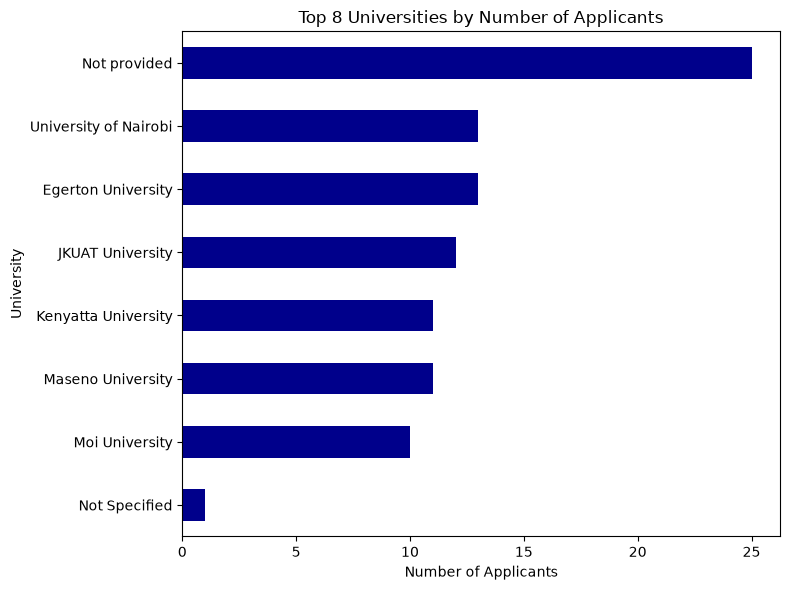

In [41]:
#Visualization
plt.figure(figsize = (8, 6))
top_universities.sort_values().plot(kind = 'barh', color = 'darkblue')
plt.title('Top 8 Universities by Number of Applicants')
plt.xlabel('Number of Applicants')
plt.ylabel('University')
plt.tight_layout()
plt.show()

*A horizontal bar chart was used to make the results easier to read and compare. Since university names can be long, horizontal bars allow the names to appear clearly without crowding the chart. The universities were arranged from the lowest to the highest number of applicants, making it easier to identify differences at a glance.*

*The results show that the University of Nairobi and Egerton University received the highest number of applications, sharing the top position. In contrast, Moi University received the fewest applications among the universities displayed. These findings help us understand which universities attracted the most and least interest from applicants in this dataset.*

*The categories "Not Specified" and "Not provided" represent records where university information was missing or not supplied in the original data. Including these categories helps us account for incomplete records instead of silently excluding them from the analysis.*

## **Step 7: How does domain popularity differ between top universities and other universities?**

In [32]:
#Checking my dataset
print(df.columns.tolist())
display(df.head())

['Applicant_Name', 'Email', 'Phone', 'Domain_Applied', 'University_Name', 'Application_date', 'Status', 'Application_Month', 'Application_Day']


,Applicant_Name,Email,Phone,Domain_Applied,University_Name,Application_date,Status,Application_Month,Application_Day
0,Valerie Miller,melanie29@example.org,8093138551x7574,Web Development,Not provided,2026-05-12,Under Review,2026-05,2026-05-12
1,Robert Johnston,briansmith@example.org,568.788.3065x7244,Web Development,Moi University,2026-05-12,Under Review,2026-05,2026-05-12
2,Breanna Solis,christopher86@example.net,0018124354182x708,Web Development,Egerton University,2026-05-13,Selected,2026-05,2026-05-13
3,Dawn Kim,kristen00@example.com,976.444.1756x4317,Web Development,Egerton University,2026-05-12,Under Review,2026-05,2026-05-12
4,Derrick Moore,kolson@example.net,5909238996,Computer Science,Maseno University,2026-05-12,Selected,2026-05,2026-05-12


In [33]:
#Loved Universities
loved_universities = [
    "University of Nairobi",
    "Egerton University"
]

*The University of Nairobi and Egerton Universities each received 13 applications and so were considered loved by most applicants.*

In [34]:
#University Group: classify each applicant's university into one of two groups
df["University_Group"] = df["University_Name"].isin(
    loved_universities
).map({
    True: "Top Universities",
    False: "Other Universities"
})

# Count applications by university group and study domain
domain_counts = pd.crosstab(
    df["Domain_Applied"],
    df["University_Group"]
)

display(domain_counts)

University_Group,Other Universities,Top Universities
Domain_Applied,,
Applied Statistics,14,5
Computer Science,3,4
Data Science,5,2
Pure Mathematics,5,3
Web Development,43,12



Among the top universities, Web Development recorded the highest number of applications, with 12 applicants while Data Science recorded the lowest number of applications, with 2 applicant.

Among the other universities, Web Development recorded the highest number of applications, with 43 applicants while Computer Science recorded the lowest number of applications, with 3 applicants.

In [35]:
#Count applications by university group
university_group_counts = df["University_Group"].value_counts()
print(university_group_counts)

University_Group
Other Universities    70
Top Universities      26
Name: count, dtype: int64


Other universities recorded 70 applications while top universities recorded 26 applications.

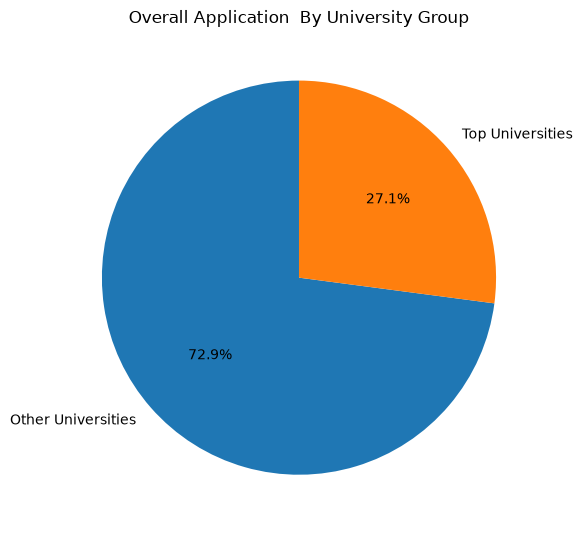

In [36]:
#Visualization
#University_Group - pie chart
plt.figure(figsize = (6, 6))
university_group_counts.plot(kind = 'pie', autopct = '%1.1f%%', startangle = 90)
plt.title('Overall Application  By University Group')
plt.ylabel('') #Removes the default awkward y-label pie charts add
plt.tight_layout()
plt.show()

Other universities recorded the highest percentage 72.9% (70 applicants) of the total applications while top uniersities recorded the lowest percentage 27.1% (26bapplicants) of the total applications.

In [37]:

# Calculate percentages within each university group
domain_percentages = domain_counts.div(
    domain_counts.sum(axis=1),
    axis=0
) * 100

# Round percentages to 2 decimal places
domain_percentages = domain_percentages.round(2)

# Display the results
display(domain_percentages)

University_Group,Other Universities,Top Universities
Domain_Applied,,
Applied Statistics,73.68,26.32
Computer Science,42.86,57.14
Data Science,71.43,28.57
Pure Mathematics,62.50,37.50
Web Development,78.18,21.82


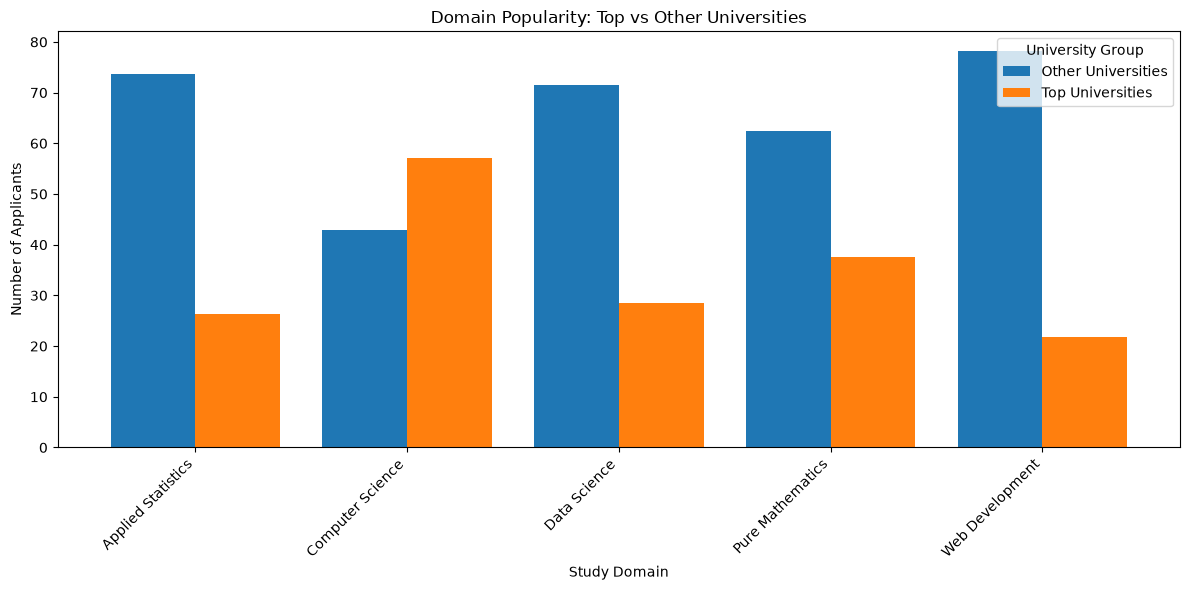

In [38]:
#Create the grouped bar chart
import matplotlib.pyplot as plt

domain_percentages.plot(
    kind="bar",
    figsize=(12, 6), #makes the chart 12 inches wide and 6 inches tall, providing enough space for the labels and bars.
    width=0.8 #controls the width of the bars to make the chart clear and easy to rea
)#creates a bar chart to compare the number of applicants across different study domains and university groups

plt.title("Domain Popularity: Top vs Other Universities") #gives the chart a descriptive title.
plt.xlabel("Study Domain")#identifies the study domains displayed along the horizontal axis.
plt.ylabel("Number of Applicants") #indicates that the vertical axis represents the number of applicants.
plt.xticks(rotation=45, ha="right") #rotates the study-domain labels by 45 degrees and aligns them to the right, making longer labels easier to read.
plt.legend(title="University Group")#identifies the university groups represented by the different bar colour
plt.tight_layout()#adjusts the spacing to prevent labels and other chart
plt.show()#displays the completed chart.

*The stacked bar chart compares the number of applicants from top universities and other universities across different domains applied. The results show that other universities had a higher number of applicants than the top universities across the domains applied.*

*This suggests that other universities collectively contributed more applicants to the different study areas represented in the dataset. The chart helps us compare applicant numbers across domains and understand how the two university groups contributed to each area of study.*

***Conclusion:** Other universities accounted for more applicants across the different domains applied than the top universities.

# **Step 8: Key Insights**

## Key Insights
- Web Development is the most popular domain by far, receiving nearly eight times more aplications than the least popular domain(Applied Statistics).
  
- Aplications peaked on 2026-05-12 and declined steadly afterward, suggesting outreach/ marketing efforts were most effective earlier in the recruitment window.
  
- While Web Development has the highest application volume, Computer Science has notably highest acceptance rate (57.1% vs 56.4%), suggesting either less competition or a stronger average applicant pool.

- The results show that the University of Nairobi and Egerton University received the highest number of applications, sharing the top position. In contrast, Moi University received the fewest applications among the universities displayed. These findings help us understand which universities attracted the most and least interest from applicants in this dataset.

- Other universities had a higher number of applicants than the top universities across the domains applied.This suggests that other universities collectively contributed more applicants to the different study areas represented in the dataset.

In [43]:
display(df)

,Applicant_Name,Email,Phone,Domain_Applied,University_Name,Application_date,Status,Application_Month,Application_Day,University_Group
0,Valerie Miller,melanie29@example.org,8093138551x7574,Web Development,Not provided,2026-05-12,Under Review,2026-05,2026-05-12,Other Universities
1,Robert Johnston,briansmith@example.org,568.788.3065x7244,Web Development,Moi University,2026-05-12,Under Review,2026-05,2026-05-12,Other Universities
2,Breanna Solis,christopher86@example.net,0018124354182x708,Web Development,Egerton University,2026-05-13,Selected,2026-05,2026-05-13,Top Universities
3,Dawn Kim,kristen00@example.com,976.444.1756x4317,Web Development,Egerton University,2026-05-12,Under Review,2026-05,2026-05-12,Top Universities
4,Derrick Moore,kolson@example.net,5909238996,Computer Science,Maseno University,2026-05-12,Selected,2026-05,2026-05-12,Other Universities
5,Jose Wells,donnaobrien@example.org,8907345073,Web Development,Not provided,2026-05-12,Under Review,2026-05,2026-05-12,Other Universities
6,Lucas Odonnell,fishermichael@example.org,3786250726,Web Development,Moi University,2026-05-13,Rejected,2026-05,2026-05-13,Other Universities
7,Ian Hoffman,atran@example.com,9598907482,Pure Mathematics,University of Nairobi,2026-05-12,Under Review,2026-05,2026-05-12,Top Universities
8,Mary Lee,amyharvey@example.org,9133507350,Web Development,JKUAT University,2026-05-12,Selected,2026-05,2026-05-12,Other Universities
9,Jamie Andrews,myersjohn@example.net,990.608.2287x5855,Web Development,Not provided,2026-05-13,Selected,2026-05,2026-05-13,Other Universities


In [44]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Applicant_Name     96 non-null     str           
 1   Email              96 non-null     str           
 2   Phone              96 non-null     str           
 3   Domain_Applied     96 non-null     str           
 4   University_Name    96 non-null     str           
 5   Application_date   96 non-null     datetime64[us]
 6   Status             96 non-null     str           
 7   Application_Month  96 non-null     period[M]     
 8   Application_Day    96 non-null     period[D]     
 9   University_Group   96 non-null     str           
dtypes: datetime64[us](1), period[D](1), period[M](1), str(7)
memory usage: 17.7 KB


In [45]:
df.to_csv("new_clean_applicants.csv", index=False)